# 01 · Data inventory and merging

**Goal of this notebook:** turn three overlapping Datafiniti review files into *one* trustworthy table of reviews and one table of products, and record every decision on the way.

**Why this comes first.** Every later result (personas, simulation, evaluation) is only as good as this table. Product identifiers in this dataset turned out to be unreliable, and the three files repeat many of the same reviews, so we merge carefully and keep an audit trail instead of just calling `pd.concat`.

### Methods used here, and why
| Method | Why we chose it |
|---|---|
| SHA-256 hash of each raw file | Proves later that the raw data was never edited (provenance). |
| Raw files copied, never changed | All cleaning happens in separate steps, so any mistake can be undone. |
| Column profile (type, % missing, uniques) | Tells us which columns are usable. Some are ~100% empty. |
| Overlap check on *(ASIN, user, text)* | Measures how many reviews repeat across files; justifies the de-duplication rule. |
| Schema mapping to one canonical table | One documented translation instead of ad-hoc renaming. |
| De-duplication on *(product, user, normalised text)* | An exact key is conservative: no fuzzy guessing that could merge two different reviews. |
| `found_in_sources` provenance column | Nothing is lost silently: we can still see which files held each review. |
| `merge(..., validate="many_to_one")` + assert | Stops the classic bug where a join silently multiplies rows. |
| Deterministic sort before dropping duplicates | Ties used to be broken arbitrarily, which changed the surviving row between runs. |
| Conflict audit for product titles | Titles differ between rows of the same ASIN; we record them instead of overwriting. |


In [1]:
# --- Setup (works in local Jupyter and on Colab) ---------------------------------------------
# Colab: run these once in a cell above, then restart if asked:
#   !git clone https://github.com/Xcode-Nancy/mirofish-consumer-simulation.git
#   %cd mirofish-consumer-simulation
#   !pip install -r requirements.txt
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repository root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

def run(script, *args):
    """Run one project script exactly as you would from a terminal, and show the end of its output.
    Notebooks call the scripts (instead of copying their code) so there is a single source of truth in src/."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), "--project-dir", str(ROOT), *map(str, args)], capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])


## Step 1 · Check the raw files
Put the three original CSV files in `data/raw/` (see `data/raw/README.md`). They are **not** committed to Git: they are large and their license has not been verified for redistribution.

In [2]:
raw = sorted(Path("data/raw").glob("*.csv"))
print(f"{len(raw)} CSV files found in data/raw:")
for f in raw: print(" -", f.name, f"({f.stat().st_size/2**20:.0f} MB)")
assert raw, "Copy the three Datafiniti CSV files into data/raw/ first (see data/raw/README.md)."

3 CSV files found in data/raw:
 - 1429_1.csv (47 MB)
 - Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv (95 MB)
 - Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv (253 MB)


## Step 2 · Inventory and profiling (Phase 1)
`inventory.py` hashes and copies each file, profiles every column, counts duplicate reviews *between* files, and looks for a price column.

In [3]:
run("inventory.py", "--raw-dir", "data/raw")

# Data inventory (Phase 1)

Generated 2026-11-14. Raw files copied unchanged to `data/raw/`; hashes in `data/source_registry.csv`.

## Files

| source | file | size MB | rows | cols | ASINs | names | brands | dates | rating range | exact dup rows |
|---|---|---|---|---|---|---|---|---|---|---|
| S01 | 1429_1.csv | 46.72 | 34,660 | 21 | 41 | 48 | 6 | 2011-11-18 to 2018-04-18 | 1.0-5.0 | 0 |
| S02 | Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv | 94.95 | 5,000 | 24 | 24 | 23 | 1 | 2014-10-24 to 2018-09-15 | 1-5 | 95 |
| S03 | Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv | 253.34 | 28,332 | 24 | 65 | 65 | 3 | 2009-02-26 to 2019-03-25 | 1-5 | 0 |

## Overlap between files

- S01 vs S02: 1,995 identical reviews (same ASIN + user + text)
- S01 vs S03: 3,550 identical reviews (same ASIN + user + text)
- S02 vs S03: 2,161 identical reviews (same ASIN + user + text)

## Price availability

- S01: price columns = NONE
- S02: price columns = NONE
- S03: price column

In [4]:
# File-level summary and the registry that records the hash of every raw file
display(pd.read_csv("reports/file_summary.csv")[["source_id","file","rows","columns","unique_asins","unique_brands","date_min","date_max","price_columns"]])
reg = pd.read_csv("data/source_registry.csv")[["source_id","dataset_version","sha256","license"]]
reg["sha256"] = reg["sha256"].str[:16] + "..."
display(reg)

,source_id,file,rows,columns,unique_asins,unique_brands,date_min,date_max,price_columns
0,S01,1429_1.csv,34660,21,41,6,2011-11-18,2018-04-18,NONE
1,S02,Datafiniti_Amazon_Consumer_Reviews_of_Amazon_P...,5000,24,24,1,2014-10-24,2018-09-15,NONE
2,S03,Datafiniti_Amazon_Consumer_Reviews_of_Amazon_P...,28332,24,65,3,2009-02-26,2019-03-25,NONE


,source_id,dataset_version,sha256,license
0,S01,1429_1.csv,e6cedcacb10fa40b...,NOT VERIFIED - check the dataset page before p...
1,S02,Datafiniti_Amazon_Consumer_Reviews_of_Amazon_P...,9718a894d000fa2c...,NOT VERIFIED - check the dataset page before p...
2,S03,Datafiniti_Amazon_Consumer_Reviews_of_Amazon_P...,9778f5b1a7e5d50d...,NOT VERIFIED - check the dataset page before p...


### What the inventory tells us
* **There is no price (or sales) column in any file.** This is the single most important fact for the project: any price effect in the simulation has to be an *assumption*, because it cannot be learned from this data.
* **The three files overlap heavily** (thousands of identical reviews between each pair), which is why de-duplication matters.
* **A few columns are almost entirely empty** (for example `reviews.id` and `reviews.didPurchase`), so we do not build anything on them.
* The `license` and source URL fields are marked **NOT VERIFIED**. Fill them in from the page you downloaded the data from before you publish anything.

## Step 3 · Merge into canonical tables (Phase 2)
`merge.py` maps the original columns to one schema, removes unusable rows (listed in `unmatched_records.csv`), removes duplicate reviews, builds a product table and joins it back with a *validated* many-to-one join.

In [5]:
run("merge.py")

load 1429_1.csv                                         0 ->   34,660  
load Datafiniti_Amazon_Consumer_Rev                     0 ->    5,000  
load Datafiniti_Amazon_Consumer_Rev                     0 ->   28,332  
concat (same logical table: reviews)               67,992 ->   67,992  
exclude unusable reviews (see unmatched_records.csv)   67,992 ->   67,952  
deduplicate (product + user + text) across sources   67,952 ->   60,872  found_in_sources keeps provenance
build products master                                  91 ->       91  one row per product_id
join reviews -> products (many_to_one)             60,872 ->   60,872  0 reviews without title

Saved:
  /tmp/repo/data/processed/reviews_canonical.csv
  /tmp/repo/data/processed/products_canonical.csv

FINAL: 60,872 reviews | 91 products | 6 brands | 5,889 reviews present in >1 source



In [6]:
# Every step of the merge, with row counts before and after
display(pd.read_csv("reports/merge_audit.csv"))

,step,rows_before,rows_after,change,note
0,load 1429_1.csv,0.0,34660,34660.0,NaN
1,load Datafiniti_Amazon_Consumer_Rev,0.0,5000,5000.0,NaN
2,load Datafiniti_Amazon_Consumer_Rev,0.0,28332,28332.0,NaN
3,concat (same logical table: reviews),67992.0,67992,0.0,NaN
4,exclude unusable reviews (see unmatched_record...,67992.0,67952,-40.0,NaN
5,deduplicate (product + user + text) across sou...,67952.0,60872,-7080.0,found_in_sources keeps provenance
6,build products master,91.0,91,0.0,one row per product_id
7,title conflicts,NaN,21,NaN,products with >1 distinct title variant; canon...
8,join reviews -> products (many_to_one),60872.0,60872,0.0,0 reviews without title


### Reading the audit
Row counts only go down at the two steps where we *intend* them to: excluding unusable rows and removing duplicates. The join back to the product table must leave the row count unchanged; the script asserts this, so a silent row multiplication is impossible.

In [7]:
reviews  = pd.read_csv("data/processed/reviews_canonical.csv", low_memory=False)
products = pd.read_csv("data/processed/products_canonical.csv")
conf = pd.read_csv("reports/conflict_audit.csv")

multi = products[products.n_title_variants > 1].product_id
print(f"{len(reviews):,} unique reviews | {len(products)} product IDs | {reviews.brand.nunique()} brands")
print(f"{reviews.found_in_sources.str.contains('[|]').sum():,} reviews appear in more than one source file")
print(f"{len(multi)} of {len(products)} product IDs carry more than one distinct title; they hold "
      f"{reviews.product_id.isin(multi).mean():.0%} of all reviews")
display(conf.head(8))

60,872 unique reviews | 91 product IDs | 6 brands
5,889 reviews appear in more than one source file
21 of 91 product IDs carry more than one distinct title; they hold 53% of all reviews


,product_id,title_variant,seen_in
0,B005PB2T0S,Amazon Kindle Lighted Leather Cover,S01
1,B005PB2T0S,Kindle Keyboard,S01
2,B00IOY8XWQ,"Amazon - Kindle Voyage - 6"" - 4GB - Black",S02
3,B00IOY8XWQ,Amazon Fire Hd 8 8in Tablet 16gb Black B018szt...,S01
4,B00IOY8XWQ,"Fire Tablet, 7 Display, Wi-Fi, 8 GB - Includes...",S01
5,B00IOY8XWQ,Kindle Paperwhite,S01
6,B00IOY8XWQ,"Kindle Paperwhite E-reader - White, 6 High-Res...",S01
7,B00IOY8XWQ,"Kindle Voyage E-reader, 6 High-Resolution Disp...",S01|S03


### Why the title conflicts matter (a real data-quality finding)
In this dataset one ASIN can carry several different product titles (for example a Kindle and a tablet under the same ASIN). About half of all reviews are affected. Consequences, and what we did about them:

* We **cannot trust the ASIN alone to say what a review is about**. So every review also keeps its *own* title (`review_source_title`), and the next notebook assigns the product category from that.
* We did **not** try to fix titles automatically with fuzzy matching: a wrong merge would be silent and hard to detect. Instead all variants are listed in `conflict_audit.csv`.
* The ASIN is kept as the unit for product-level evaluation, so product-level results should be read with this limitation in mind.

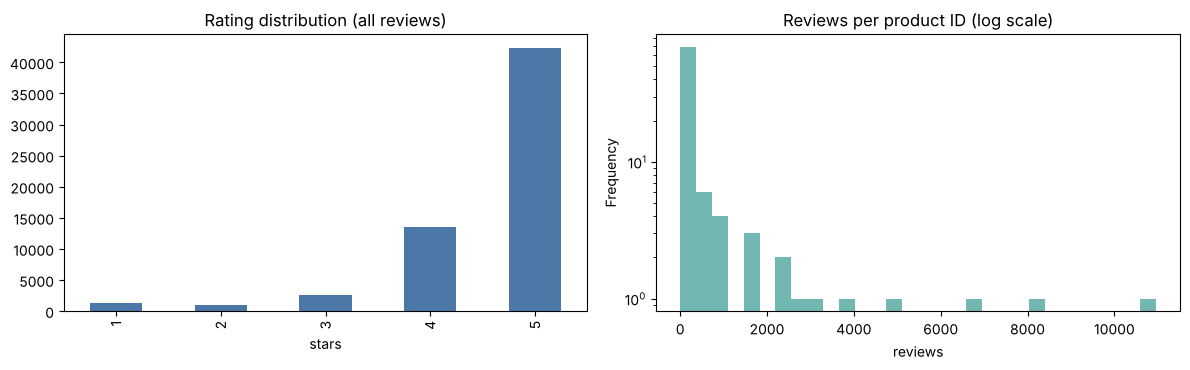

Share of 4-5 star reviews: 91.9%


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
reviews.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4c78a8"); ax[0].set_title("Rating distribution (all reviews)"); ax[0].set_xlabel("stars")
reviews.product_id.value_counts().plot.hist(bins=30, ax=ax[1], color="#72b7b2", log=True); ax[1].set_title("Reviews per product ID (log scale)"); ax[1].set_xlabel("reviews")
plt.tight_layout(); plt.show()
print(f"Share of 4-5 star reviews: {(reviews.rating >= 4).mean():.1%}")

### Take-aways
* The data is **strongly positive** (the great majority of reviews are 4 or 5 stars). That leaves little variation for any model to explain, and it will limit what the evaluation can show.
* Review counts per product are **very uneven**: a few products have thousands of reviews and many have only a few dozen, so product-level statistics for small products are noisy.

**Next:** `02_knowledge_layer_and_personas.ipynb` picks one product category and builds the aspects, retrieval index and personas.